# 08 - DeepLog-style LSTM on full HDFS

An LSTM learns to predict the next event from the previous 10, trained only on normal blocks (Du et al., 2017).

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.evaluation.metrics import evaluate
from src.models.lstm import DeepLogLSTM, build_vocab, detect, make_windows, train
from src.models.unsupervised import time_split

DOCS = ROOT / "docs"
H, SEED, N_TRAIN_BLOCKS = 10, 42, 5000
torch.manual_seed(SEED)

sequences = pd.read_parquet(ROOT / "data" / "processed" / "hdfs_sequences.parquet")
templates = pd.read_csv(ROOT / "data" / "processed" / "hdfs_templates.csv")

## Training data

Same 70/30 split as notebooks 06 and 07. The model trains on the first 5,000 normal blocks of the training part, with 10% of them held out for validation.

In [2]:
train_part, test = time_split(sequences, train_frac=0.7)
normal_blocks = train_part[train_part["Label"] == 0].head(N_TRAIN_BLOCKS)["EventSequence"].tolist()

vocab = build_vocab(templates["EventId"])
train_events = {e for seq in normal_blocks for e in seq}

rng = np.random.default_rng(SEED)
val_mask = rng.random(len(normal_blocks)) < 0.1
X_tr, y_tr, _ = make_windows([s for s, v in zip(normal_blocks, val_mask) if not v], vocab, H)
X_val, y_val, _ = make_windows([s for s, v in zip(normal_blocks, val_mask) if v], vocab, H)

print(f"Events: {len(vocab)} in total, {len(train_events)} seen in training")
print(f"Training windows: {len(y_tr):,} ({(~val_mask).sum()} blocks)   validation windows: {len(y_val):,} ({val_mask.sum()} blocks)")

Events: 45 in total, 17 seen in training
Training windows: 113,038 (4508 blocks)   validation windows: 12,222 (492 blocks)


## Train

In [3]:
model = DeepLogLSTM(num_events=len(vocab), embed_dim=32, hidden_size=64, num_layers=2)
history, train_seconds = train(model, X_tr, y_tr, X_val, y_val, epochs=30, patience=3, seed=SEED)

print(f"\nTraining time: {train_seconds:.1f} s")
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

epoch  1  train loss 0.5035  val loss 0.5026


epoch  2  train loss 0.2953  val loss 0.2900


epoch  3  train loss 0.2598  val loss 0.2538


epoch  4  train loss 0.2448  val loss 0.2387


epoch  5  train loss 0.2404  val loss 0.2357


epoch  6  train loss 0.2344  val loss 0.2288


... (8 outputs left out)

epoch 15  train loss 0.2255  val loss 0.2206


epoch 16  train loss 0.2261  val loss 0.2229


epoch 17  train loss 0.2250  val loss 0.2208


epoch 18  train loss 0.2250  val loss 0.2209
early stopping after epoch 18

Training time: 98.8 s
Parameters: 62,830


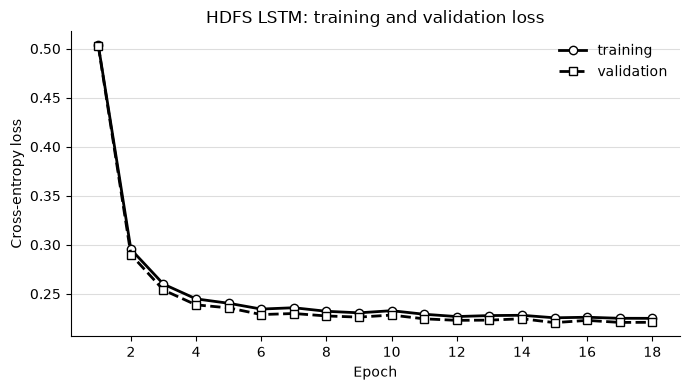

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(history["epoch"], history["train_loss"], color="black", linewidth=2, marker="o", markersize=6,
        markerfacecolor="white", label="training")
ax.plot(history["epoch"], history["val_loss"], color="black", linewidth=2, linestyle="--", marker="s", markersize=6,
        markerfacecolor="white", label="validation")

ax.set_xlabel("Epoch")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_ylabel("Cross-entropy loss")
ax.set_title("HDFS LSTM: training and validation loss")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.grid(True, color="#dddddd", linewidth=0.8)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig(DOCS / "hdfs_lstm_loss.png", dpi=150, facecolor="white")
plt.show()

## Detection on the test set

A block is anomalous if any event is not in the model's top-k predictions, or if it contains an event never seen in training.

In [5]:
test_seqs, y_test = test["EventSequence"].tolist(), test["Label"].to_numpy()

rows = []
for k in [5, 9, 12]:
    start = time.perf_counter()
    pred = detect(model, test_seqs, vocab, train_events, k=k, h=H)
    seconds = time.perf_counter() - start
    m = evaluate(y_test, pred)
    rows.append({"k": k, "precision": m["precision"], "recall": m["recall"], "f1": m["f1"],
                 "false_alarm_rate": m["false_alarm_rate"], "detection_seconds": seconds})

results = pd.DataFrame(rows)
results.round(4).to_csv(DOCS / "hdfs_lstm_results.csv", index=False)
results.style.format({c: "{:.4f}" for c in ["precision", "recall", "f1", "false_alarm_rate"]} | {"detection_seconds": "{:.1f}"}).hide(axis="index")

k,precision,recall,f1,false_alarm_rate,detection_seconds
5,0.0292,0.8174,0.0565,0.5983,30.1
9,0.0296,0.8174,0.0572,0.5905,31.1
12,0.7608,0.8174,0.7880,0.0057,32.1


At k=5 and 9 most false alarms are normal test blocks without the `E10 E13 E13` events that almost every one of the first 5,000 training blocks has, so the model has not seen their context before `E17`.

## Save the model

In [6]:
(ROOT / "models").mkdir(exist_ok=True)
torch.save({
    "state_dict": model.state_dict(),
    "vocab": vocab,
    "train_events": sorted(train_events),
    "config": {"h": H, "embed_dim": 32, "hidden_size": 64, "num_layers": 2},
}, ROOT / "models" / "hdfs_lstm.pt")